## Imports

In [1]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, AveragePooling2D, Dense, Flatten, Dropout, Input, concatenate, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import os

## Dataset Config

In [2]:
dataset_path = "/kaggle/input/lung-cancer-dataset-3/data_v2"
input_shape = (250, 250)

In [3]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "train"),
    image_size=input_shape,  # Resize images
    batch_size=32,
    shuffle=True,
    # label_mode="categorical",
    label_mode="binary",
    color_mode="grayscale"  # only if loading grayscale images
)

val_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "val"),
    image_size=input_shape,  # Resize images
    batch_size=32,
    shuffle=True,
    # label_mode="categorical",
    label_mode="binary",
    color_mode="grayscale"   # only if loading grayscale images
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "test"),
    image_size=input_shape,  # Resize images
    batch_size=32,
    shuffle=True,
    # label_mode="categorical",
    label_mode="binary",
    color_mode="grayscale"   # only if loading grayscale images
)

train_dataset.class_names

Found 3380 files belonging to 2 classes.
Found 896 files belonging to 2 classes.
Found 1128 files belonging to 2 classes.


['benign', 'malignant']

## Data Augmentation

In [4]:
data_augmentation_layer = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),  # Randomly flip images
    tf.keras.layers.RandomRotation(0.7),                   # Randomly rotate images
])

# rescale_layer = tf.keras.layers.Rescaling(1./255)  # Rescale to [0, 1]
rescale_layer = tf.keras.layers.Rescaling(1./127.5, offset=-1)  # Rescale to [-1, 1]

In [5]:
# Apply data augmentation and preprocessing to the datasets

train_dataset = train_dataset.map(lambda x, y: (data_augmentation_layer(x), y))
train_dataset = train_dataset.map(
    lambda x, y: (rescale_layer(x), y)
)

val_dataset = val_dataset.map(lambda x, y: (data_augmentation_layer(x), y))
val_dataset = val_dataset.map(
    lambda x, y: (rescale_layer(x), y)
)

test_dataset = test_dataset.map(lambda x, y: (data_augmentation_layer(x), y))
test_dataset = test_dataset.map(
    lambda x, y: (rescale_layer(x), y)
)

## Custom Layers (CBAM)

In [6]:
from tensorflow.keras.layers import Layer, Dense, Conv2D, GlobalAveragePooling2D, GlobalMaxPooling2D, Reshape, Add, Activation, Multiply, Concatenate, MaxPooling2D

class CBAMLayer(Layer):
    def __init__(self, ratio=8, kernel_size=7, **kwargs):
        super(CBAMLayer, self).__init__(**kwargs)
        self.ratio = ratio
        self.kernel_size = kernel_size

    def build(self, input_shape):
        self.channel = input_shape[-1]  # Get the number of channels from input shape
        
        # Define shared MLP layers for channel attention
        self.shared_dense_one = Dense(self.channel // self.ratio, activation="relu", use_bias=True, kernel_initializer="he_normal")
        self.shared_dense_two = Dense(self.channel, use_bias=True, kernel_initializer="he_normal")

        # Define the spatial attention convolutional layer
        self.spatial_conv = Conv2D(filters=1, kernel_size=self.kernel_size, strides=1, padding="same", activation="sigmoid", use_bias=False, kernel_initializer="he_normal")

        super(CBAMLayer, self).build(input_shape)  # Important to call this

    def call(self, inputs, **kwargs):
        # === Channel Attention ===
        avg_pool = GlobalAveragePooling2D()(inputs)
        max_pool = GlobalMaxPooling2D()(inputs)
        
        avg_pool = Reshape((1, 1, self.channel))(avg_pool)
        max_pool = Reshape((1, 1, self.channel))(max_pool)
        
        avg_fc = self.shared_dense_two(self.shared_dense_one(avg_pool))
        max_fc = self.shared_dense_two(self.shared_dense_one(max_pool))

        channel_attention = Activation('sigmoid')(Add()([avg_fc, max_fc]))
        channel_refined = Multiply()([inputs, channel_attention])

        # === Spatial Attention ===
        avg_spatial = tf.reduce_mean(channel_refined, axis=-1, keepdims=True)
        max_spatial = tf.reduce_max(channel_refined, axis=-1, keepdims=True)

        concat = Concatenate(axis=-1)([avg_spatial, max_spatial])
        spatial_attention = self.spatial_conv(concat)
        
        output = Multiply()([channel_refined, spatial_attention])
        return output

    def get_config(self):
        config = super(CBAMLayer, self).get_config()
        config.update({"ratio": self.ratio, "kernel_size": self.kernel_size})
        return config

In [7]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, AveragePooling2D, Dense, Flatten, Dropout, Input, concatenate, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.regularizers import l2


def inception_module(x, filters):
    f1, f2_reduce, f2, f3_reduce, f3, f4 = filters
    
    # 1x1 Convolution Branch
    conv1 = Conv2D(f1, (1,1), padding='same', kernel_regularizer=l2(0.0005))(x)
    conv1 = BatchNormalization()(conv1)
    conv1 = Activation('relu')(conv1)

    # 1x1 -> 3x3 Convolution Branch
    conv3_reduce = Conv2D(f2_reduce, (1,1), padding='same', kernel_regularizer=l2(0.0005))(x)
    conv3_reduce = BatchNormalization()(conv3_reduce)
    conv3_reduce = Activation('relu')(conv3_reduce)
    
    conv3 = Conv2D(f2, (3,3), padding='same', kernel_regularizer=l2(0.0005))(conv3_reduce)
    conv3 = BatchNormalization()(conv3)
    conv3 = Activation('relu')(conv3)

    # 1x1 -> 5x5 Convolution Branch
    conv5_reduce = Conv2D(f3_reduce, (1,1), padding='same', kernel_regularizer=l2(0.0005))(x)
    conv5_reduce = BatchNormalization()(conv5_reduce)
    conv5_reduce = Activation('relu')(conv5_reduce)
    
    conv5 = Conv2D(f3, (5,5), padding='same', kernel_regularizer=l2(0.0005))(conv5_reduce)
    conv5 = BatchNormalization()(conv5)
    conv5 = Activation('relu')(conv5)

    # MaxPooling -> 1x1 Convolution Branch
    pool_proj = MaxPooling2D((3,3), strides=(1,1), padding='same')(x)
    pool_proj = Conv2D(f4, (1,1), padding='same', kernel_regularizer=l2(0.0005))(pool_proj)
    pool_proj = BatchNormalization()(pool_proj)
    pool_proj = Activation('relu')(pool_proj)

    # Concatenate all branches
    output = concatenate([conv1, conv3, conv5, pool_proj], axis=-1)
    # output = CBAMLayer()(output)

    return output


## Main Model

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Layer, Input, Dense, Conv2D, MaxPooling2D, AveragePooling2D
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Concatenate, Activation, Flatten
from tensorflow.keras.optimizers import Adam


input_layer = Input(shape=(*input_shape, 1))

x = Conv2D(64, (7,7), strides=(2,2), padding='same', activation='relu', kernel_regularizer=l2(0.0005))(input_layer)
x = CBAMLayer()(x)
x = BatchNormalization()(x)
x = MaxPooling2D((3,3), strides=(2,2), padding='same')(x)

x = Conv2D(128, (5,5), padding='same', activation='relu', kernel_regularizer=l2(0.0005))(x)
x = CBAMLayer()(x)
x = BatchNormalization()(x)

x = Conv2D(192, (3,3), padding='same', activation='relu', kernel_regularizer=l2(0.0005))(x)
x = CBAMLayer()(x)
x = BatchNormalization()(x)
x = MaxPooling2D((3,3), strides=(2,2), padding='same')(x)

x = inception_module(x, [64, 96, 128, 16, 32, 32])
x = inception_module(x, [128, 128, 192, 32, 96, 64])
# x = CBAMLayer()(x)
x = MaxPooling2D((3,3), strides=(2,2), padding='same')(x)

x = inception_module(x, [192, 96, 208, 16, 48, 64])
x = inception_module(x, [160, 112, 224, 24, 64, 64])
x = inception_module(x, [128, 128, 256, 24, 64, 64])
x = inception_module(x, [112, 144, 288, 32, 64, 64])
x = inception_module(x, [256, 160, 320, 32, 128, 128])
# x = CBAMLayer()(x)
x = MaxPooling2D((3,3), strides=(2,2), padding='same')(x)

x = inception_module(x, [256, 160, 320, 32, 128, 128])
x = inception_module(x, [384, 192, 384, 48, 128, 128])
# x = CBAMLayer()(x)

x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu', kernel_regularizer=l2(0.0005))(x)
x = Dropout(0.5)(x)  # Increased Dropout
x = Dense(1024, activation='relu', kernel_regularizer=l2(0.0005))(x)
x = Dropout(0.4)(x)
x = Dense(512, activation='relu', kernel_regularizer=l2(0.0005))(x)
x = Dropout(0.3)(x)
x = Dense(512, activation='relu', kernel_regularizer=l2(0.0005))(x)
x = Dropout(0.2)(x)
x = Dense(1, activation='sigmoid')(x)  # FIXED output layer



model = Model(inputs=input_layer, outputs=x)

# Print model summary
model.summary()

Model: "functional_2"

 Trainable params: 8,047,143 (30.70 MB)

 Non-trainable params: 14,688 (57.38 KB)

## Model Configs

In [11]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.metrics import categorical_accuracy, binary_accuracy


optimizer = AdamW(
   learning_rate=0.0001,
   beta_1=0.9,
   beta_2=0.999,
   epsilon=1e-07,
   weight_decay=1e-5
)

model.compile(
    optimizer=optimizer, 
    # loss='categorical_crossentropy', 
    loss='binary_crossentropy', 
    metrics=[
        # categorical_accuracy,
        # binary_accuracy,
        'accuracy',
        tf.keras.metrics.AUC(name='auc'),  # ROC AUC
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.F1Score(name='f1')
    ])

## Train Model

In [12]:
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
model_checkpoint = ModelCheckpoint("best_model_google_net_2.keras", save_best_only=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)

history = model.fit(
    train_dataset,
    epochs=30,  # Increased epochs
    validation_data=val_dataset,  
    callbacks=[reduce_lr, early_stopping, model_checkpoint]
)


Epoch 1/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 166s 701ms/step - accuracy: 0.5361 - auc: 0.5637 - f1: 0.6789 - loss: 5.9130 - precision: 0.5478 - recall: 0.5641 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_f1: 0.6667 - val_loss: 6.0213 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 2/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 16s 149ms/step - accuracy: 0.6859 - auc: 0.7378 - f1: 0.6849 - loss: 5.6683 - precision: 0.6829 - recall: 0.7403 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_f1: 0.6667 - val_loss: 7.1771 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 3/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 16s 150ms/step - accuracy: 0.8241 - auc: 0.8930 - f1: 0.6776 - loss: 5.2043 - precision: 0.8555 - recall: 0.7907 - val_accuracy: 0.5000 - val_auc: 0.5000 - val_f1: 0.6667 - val_loss: 8.9170 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 5/30
106/106 ━━━━━━━━━━━━━━━━━━━━ 16s 148ms/step - accuracy:

## Save Model

In [19]:
model.save('/kaggle/working/google_net_2.keras')

## Results

In [13]:
result = model.evaluate(test_dataset)

36/36 ━━━━━━━━━━━━━━━━━━━━ 13s 349ms/step - accuracy: 0.9300 - auc: 0.9782 - f1: 0.6631 - loss: 2.3777 - precision: 0.9480 - recall: 0.9090


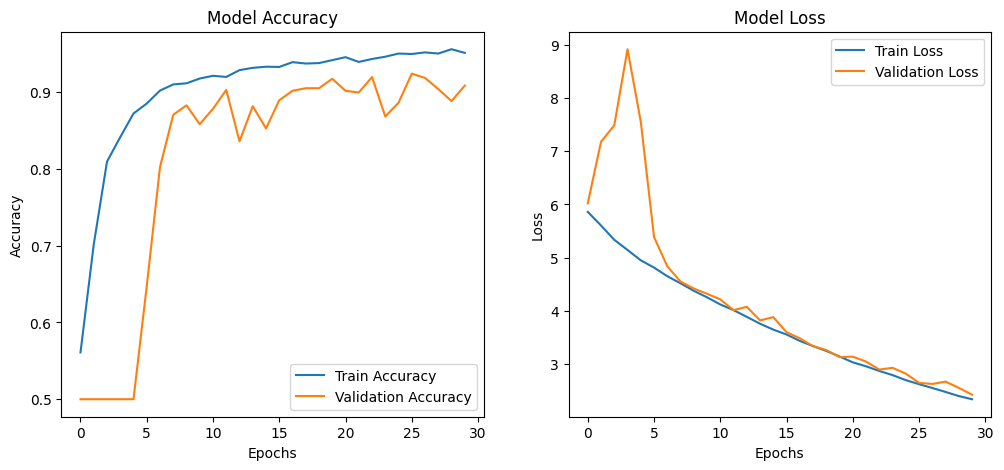

In [14]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy and loss
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Model Accuracy')

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Model Loss')

plt.show()

In [15]:
import numpy as np 

# Convert dataset to NumPy arrays
def get_labels_and_predictions(dataset, model):
    y_true, y_pred_prob = [], []

    for images, labels in dataset:
        y_true.extend(labels.numpy())  # Convert tensor to NumPy
        y_pred_prob.extend(model.predict(images))  # Get predicted probabilities

    y_true = np.array(y_true)
    y_pred_prob = np.array(y_pred_prob).flatten()  # Flatten if needed
    y_pred = (y_pred_prob > 0.5).astype(int)  # Convert probabilities to binary labels

    return y_true, y_pred, y_pred_prob

y_true, y_pred, y_pred_prob = get_labels_and_predictions(test_dataset, model)


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━

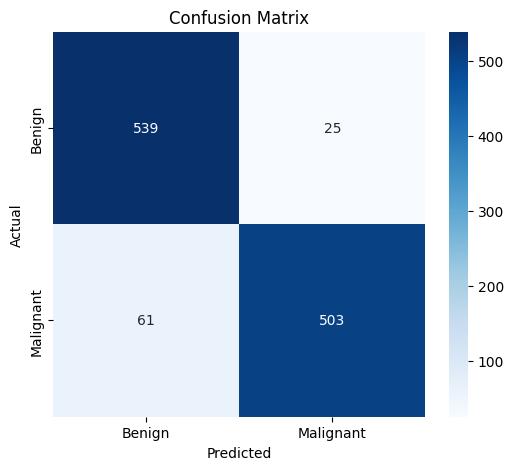

In [16]:
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get predictions
# y_pred = (model.predict(X_test) > 0.5).astype("int32")  # Convert probabilities to 0/1
cm = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [17]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=['Benign', 'Malignant']))


              precision    recall  f1-score   support

      Benign       0.90      0.96      0.93       564
   Malignant       0.95      0.89      0.92       564

    accuracy                           0.92      1128
   macro avg       0.93      0.92      0.92      1128
weighted avg       0.93      0.92      0.92      1128



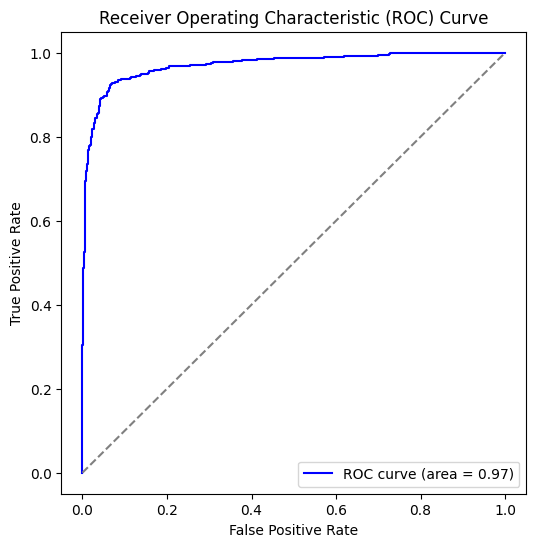

In [18]:
from sklearn.metrics import roc_curve, auc

# Get predicted probabilities
# y_prob = model.predict(X_test).ravel()  # Flatten array

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_true, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal reference line
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.show()
